<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/statistics/BrownianMotion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

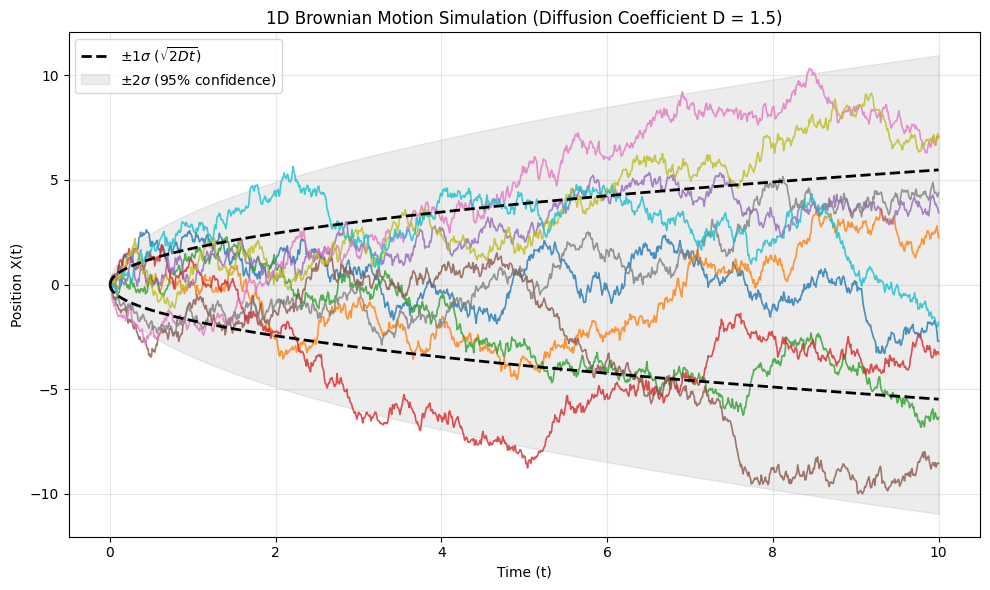

In [22]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_brownian_motion(D: float, T: float, dt: float, num_paths: int = 5):
    """
    Simulates 1D Brownian motion as a cumulative sum of normal random variables.

    Parameters:
    D (float): Diffusion coefficient (units: length^2 / time)
    T (float): Total simulation time
    dt (float): Time step size
    num_paths (int): Number of independent trajectories to simulate
    """
    # Number of time steps
    N = int(T / dt)
    t = np.linspace(0, T, N + 1)

    # Standard deviation of each step: sigma = sqrt(2 * D * dt)
    # Note: In financial math (standard Wiener process), variance is simply dt (so D = 0.5)
    step_std = np.sqrt(2 * D * dt)

    # Generate random increments: shape (num_paths, N)
    # Each increment is drawn from N(0, 2 * D * dt)
    increments = np.random.normal(loc=0.0, scale=step_std, size=(num_paths, N))

    # Prepend zeros so all paths start at X(0) = 0
    X = np.zeros((num_paths, N + 1))
    X[:, 1:] = np.cumsum(increments, axis=1)

    return t, X

# --- Parameters ---
D = 1.5          # Diffusion coefficient
T = 10.0         # Total time (seconds)
dt = 0.01        # Time step (seconds)
num_paths = 10   # Number of particles/paths

# Run simulation
t, trajectories = simulate_brownian_motion(D, T, dt, num_paths)

# --- Plotting ---
plt.figure(figsize=(10, 6))

# Plot each simulated path
for i in range(num_paths):
    plt.plot(t, trajectories[i], lw=1.2, alpha=0.8)

# Plot theoretical +/- 1 and 2 standard deviation envelopes: std(t) = sqrt(2 * D * t)
theoretical_std = np.sqrt(2 * D * t)
plt.plot(t, theoretical_std, 'k--', lw=2, label=r'$\pm 1\sigma$ ($\sqrt{2Dt}$)')
plt.plot(t, -theoretical_std, 'k--', lw=2)
plt.fill_between(t, -2 * theoretical_std, 2 * theoretical_std, color='gray', alpha=0.15, label=r'$\pm 2\sigma$ (95% confidence)')

plt.title(f"1D Brownian Motion Simulation (Diffusion Coefficient D = {D})")
plt.xlabel("Time (t)")
plt.ylabel("Position X(t)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

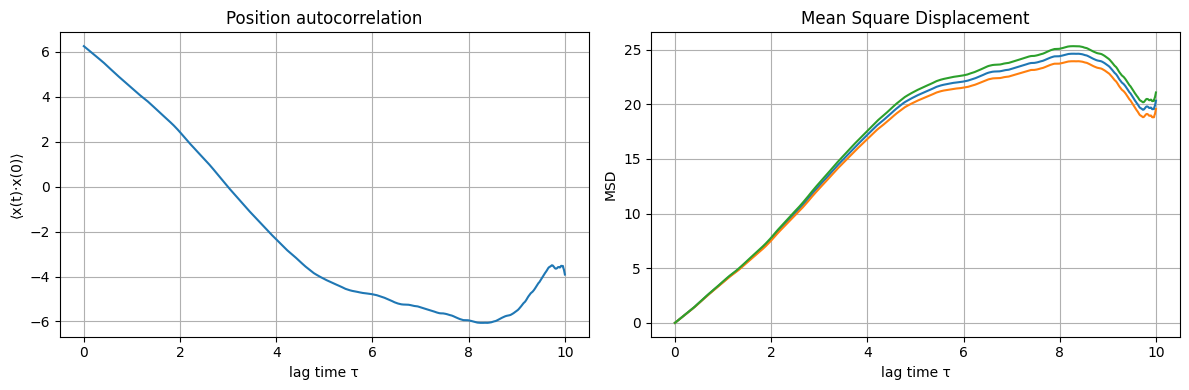

corrt shape: (10, 1001), N: 1000


In [23]:

def autocorrelation_fft(v, t=None, normalize=True):
    """
    Compute the autocorrelation function of a 1D signal v(t) using FFT.

    Parameters
    ----------
    v : array_like, shape (N,)
        Signal values.
    t : array_like, shape (N,), optional
        Time axis. If None, integer indices are used.
    normalize : bool
        If True, normalize so that C(0) = 1.

    Returns
    -------
    tau : ndarray, shape (N,)
        Lag times (positive lags only).
    C   : ndarray, shape (N,)
        Autocorrelation function at each lag.
    """
    v = np.asarray(v, dtype=float)
    N = len(v)

    # Subtract mean (standard definition of autocorrelation)
    v = v - np.mean(v)

    # Zero-pad to length 2N to avoid circular (wrap-around) correlation
    v_padded = np.zeros(2 * N)
    v_padded[:N] = v

    # FFT, power spectrum, inverse FFT
    V = np.fft.fft(v_padded)
    S = V * np.conj(V)          # power spectrum = |V(f)|^2
    C_full = np.fft.ifft(S).real

    # Keep only positive lags (first N points)
    C = C_full[:N]

    # Normalise by the number of contributing pairs at each lag
    # (unbiased estimator: divide by N - lag instead of N)
    counts = N - np.arange(N)   # [N, N-1, N-2, ..., 1]
    C = C / counts

    if normalize:
        C = C / C[0]            # C(0) = 1

    # Build lag axis
    if t is not None:
        dt = t[1] - t[0]        # assumes uniform sampling
        tau = np.arange(N) * dt
    else:
        tau = np.arange(N)

    return tau, C

#########################################

N = int(T / dt)
corrt = np.zeros((num_paths, N+1))
msd   = np.zeros((num_paths, N+1))

F, axes = plt.subplots(1, 2, figsize=(12, 4))

for i in range(num_paths):
    x = trajectories[i, :]

    # Autocorrelation of position (normalize=False to keep physical units)
    tau, C = autocorrelation_fft(x, t, normalize=False)
    corrt[i, :] = C

    # MSD = 2 * (<x²> - <x(t)·x(0)>)
    # C[0] = <x²> (variance, since mean was subtracted inside the function)
    msd[i, :] = 2 * (C[0] - C)

# Average over paths
mean_corr = corrt.mean(axis=0)

mean_msd  = msd.mean(axis=0)
std_msd  = msd.std(axis=0)

axes[0].plot(tau, mean_corr)
axes[0].set_xlabel('lag time τ')
axes[0].set_ylabel('⟨x(t)·x(0)⟩')
axes[0].set_title('Position autocorrelation')
axes[0].grid(True)

axes[1].plot(tau, mean_msd)
axes[1].plot(tau, mean_msd - std_msd/np.sqrt(mean_msd.size))
axes[1].plot(tau, mean_msd + std_msd/np.sqrt(mean_msd.size))
axes[1].set_xlabel('lag time τ')
axes[1].set_ylabel('MSD')
axes[1].set_title('Mean Square Displacement')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f'corrt shape: {corrt.shape}, N: {N}')

